In [1]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from models.lstm import run_lstm
from utils.plots import plot_forecast
from models.shap import explain_variables

c:\TCC\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Buscando dados

In [ ]:
vale_csv = "data/vale.csv"

if not os.path.exists(vale_csv):
    vale3_dataset = load_stock(STOCKS["vale"], "vale", force=True)
    vale3_dataset.head(10)

vale3_dataset = pd.read_csv(vale_csv)

SGSError: SGS time series code=432 server error (status 502)

In [ ]:
vale3_dataset

,date,vale_close,vale_high,vale_low,vale_open,vale_volume,ibovespa,vix,selic_daily,selic_goal,ipca,fx_usd,gdp,unemployment
0,2015-01-02,9.710408,10.016140,9.610018,9.902061,5658400,48512.0,17.790001,0.043739,11.75,1.24,2.6929,473967.4,6.9
1,2015-01-05,9.564384,9.641958,9.359043,9.473122,8603000,47517.0,19.920000,0.043739,11.75,1.24,2.7107,473967.4,6.9
2,2015-01-06,9.947690,10.098274,9.614579,9.614579,9879900,48001.0,21.120001,0.043739,11.75,1.24,2.7023,473967.4,6.9
3,2015-01-07,10.312744,10.408570,10.025265,10.184975,6130900,49463.0,19.309999,0.043739,11.75,1.24,2.6807,473967.4,6.9
4,2015-01-08,10.422259,10.440512,10.089149,10.390317,4667300,49943.0,17.010000,0.043739,11.75,1.24,2.6919,473967.4,6.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2732,2025-12-22,70.929672,71.367394,68.877263,69.091260,27853000,158142.0,14.080000,0.055131,15.00,0.33,5.5389,1084318.8,5.1
2733,2025-12-23,70.910225,71.523027,70.598959,71.231219,17140900,160456.0,14.000000,0.055131,15.00,0.33,5.5643,1084318.8,5.1
2734,2025-12-26,71.124222,71.347940,70.637869,70.871316,16368800,160897.0,13.600000,0.055131,15.00,0.33,5.5413,1084318.8,5.1
2735,2025-12-29,70.151512,71.727290,69.742970,71.192307,19963700,160490.0,14.200000,0.055131,15.00,0.33,5.5739,1084318.8,5.1


In [ ]:
print(vale3_dataset.isna().sum())

date            0
vale_close      0
vale_high       0
vale_low        0
vale_open       0
vale_volume     0
ibovespa        0
vix             0
selic_daily     0
selic_goal      0
ipca            0
fx_usd          0
gdp             0
unemployment    0
dtype: int64


## ARIMA

In [ ]:
train_vale, test_vale = split_temporal(vale3_dataset)
res_vale = run_arima(train_vale, test_vale, "vale")

--- Identificando ordem do ARIMA para VALE ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=5363.432, Time=0.56 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=5359.339, Time=0.08 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=5361.287, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=5361.284, Time=0.07 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=5358.389, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=5361.477, Time=0.23 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 1.016 seconds
Ordem ARIMA selecionada: (0, 1, 0)
ARIMA(0, 1, 0) vale    RMSE: 0.7249 | MAE: 0.5312 | MAPE: 1.03% | Acurácia direcional: n/a


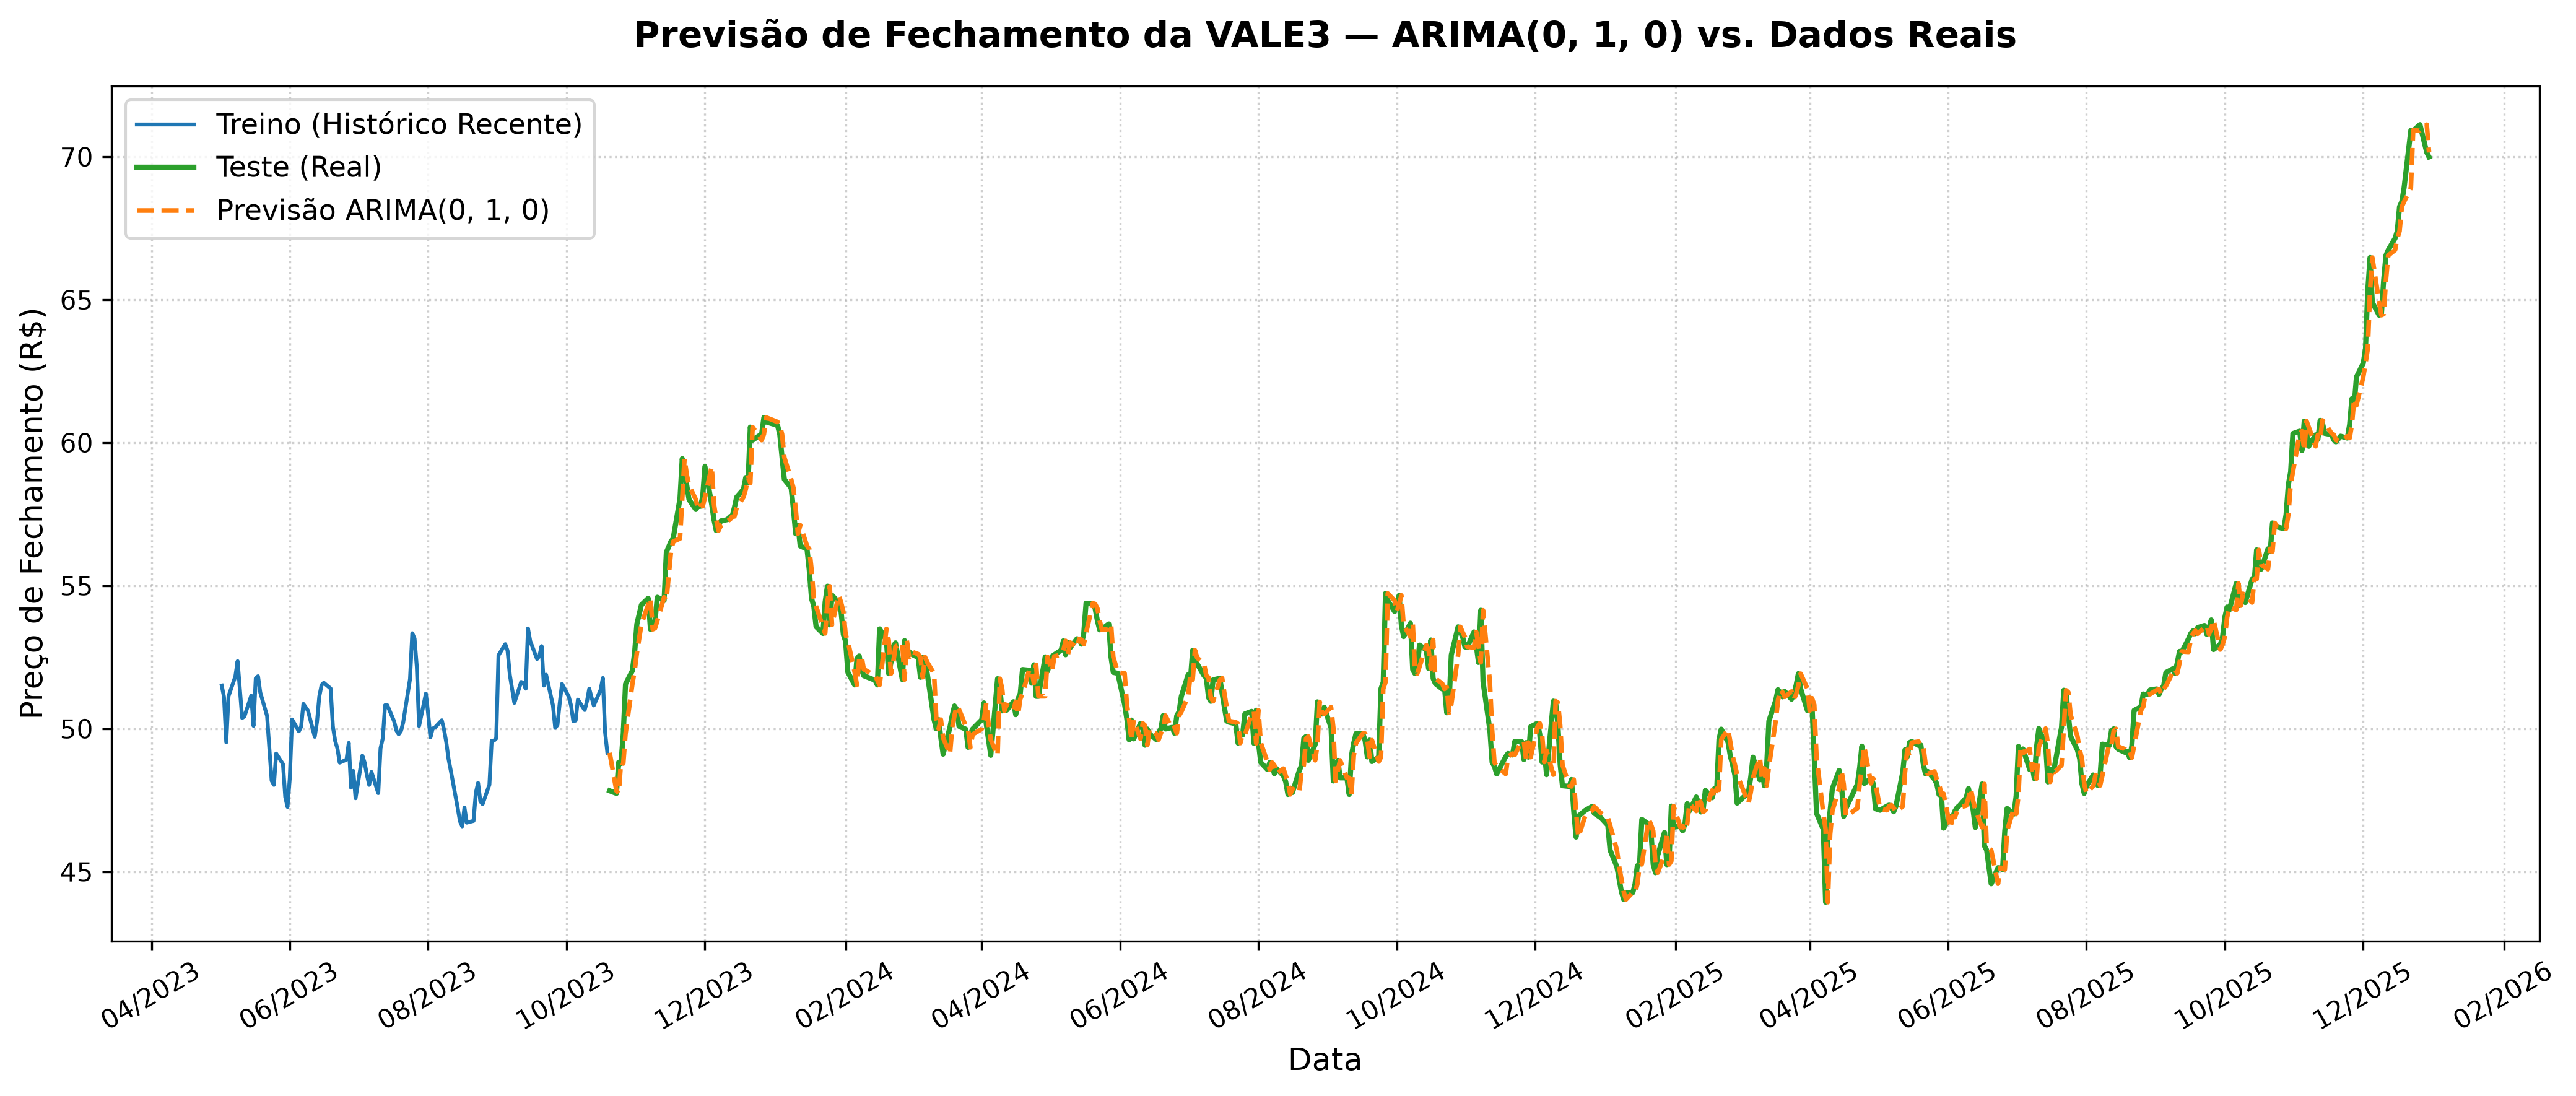

In [ ]:
plot_forecast(
    train_vale, test_vale,
    predictions=res_vale["predictions"],
    stock_name="vale",
    model_name=f"ARIMA{res_vale['order']}",
    ticker_label="VALE3",
)

## XGBooster

--- XGBoost VALE: 37 features, 2186 treino / 548 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Melhor RMSE médio (validação): 7.6004
XGBoost vale           RMSE: 0.7308 | MAE: 0.5523 | MAPE: 1.07% | Acurácia direcional: 60.58%
Naive vale             RMSE: 0.7249 | MAE: 0.5312 | MAPE: 1.03% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.0000


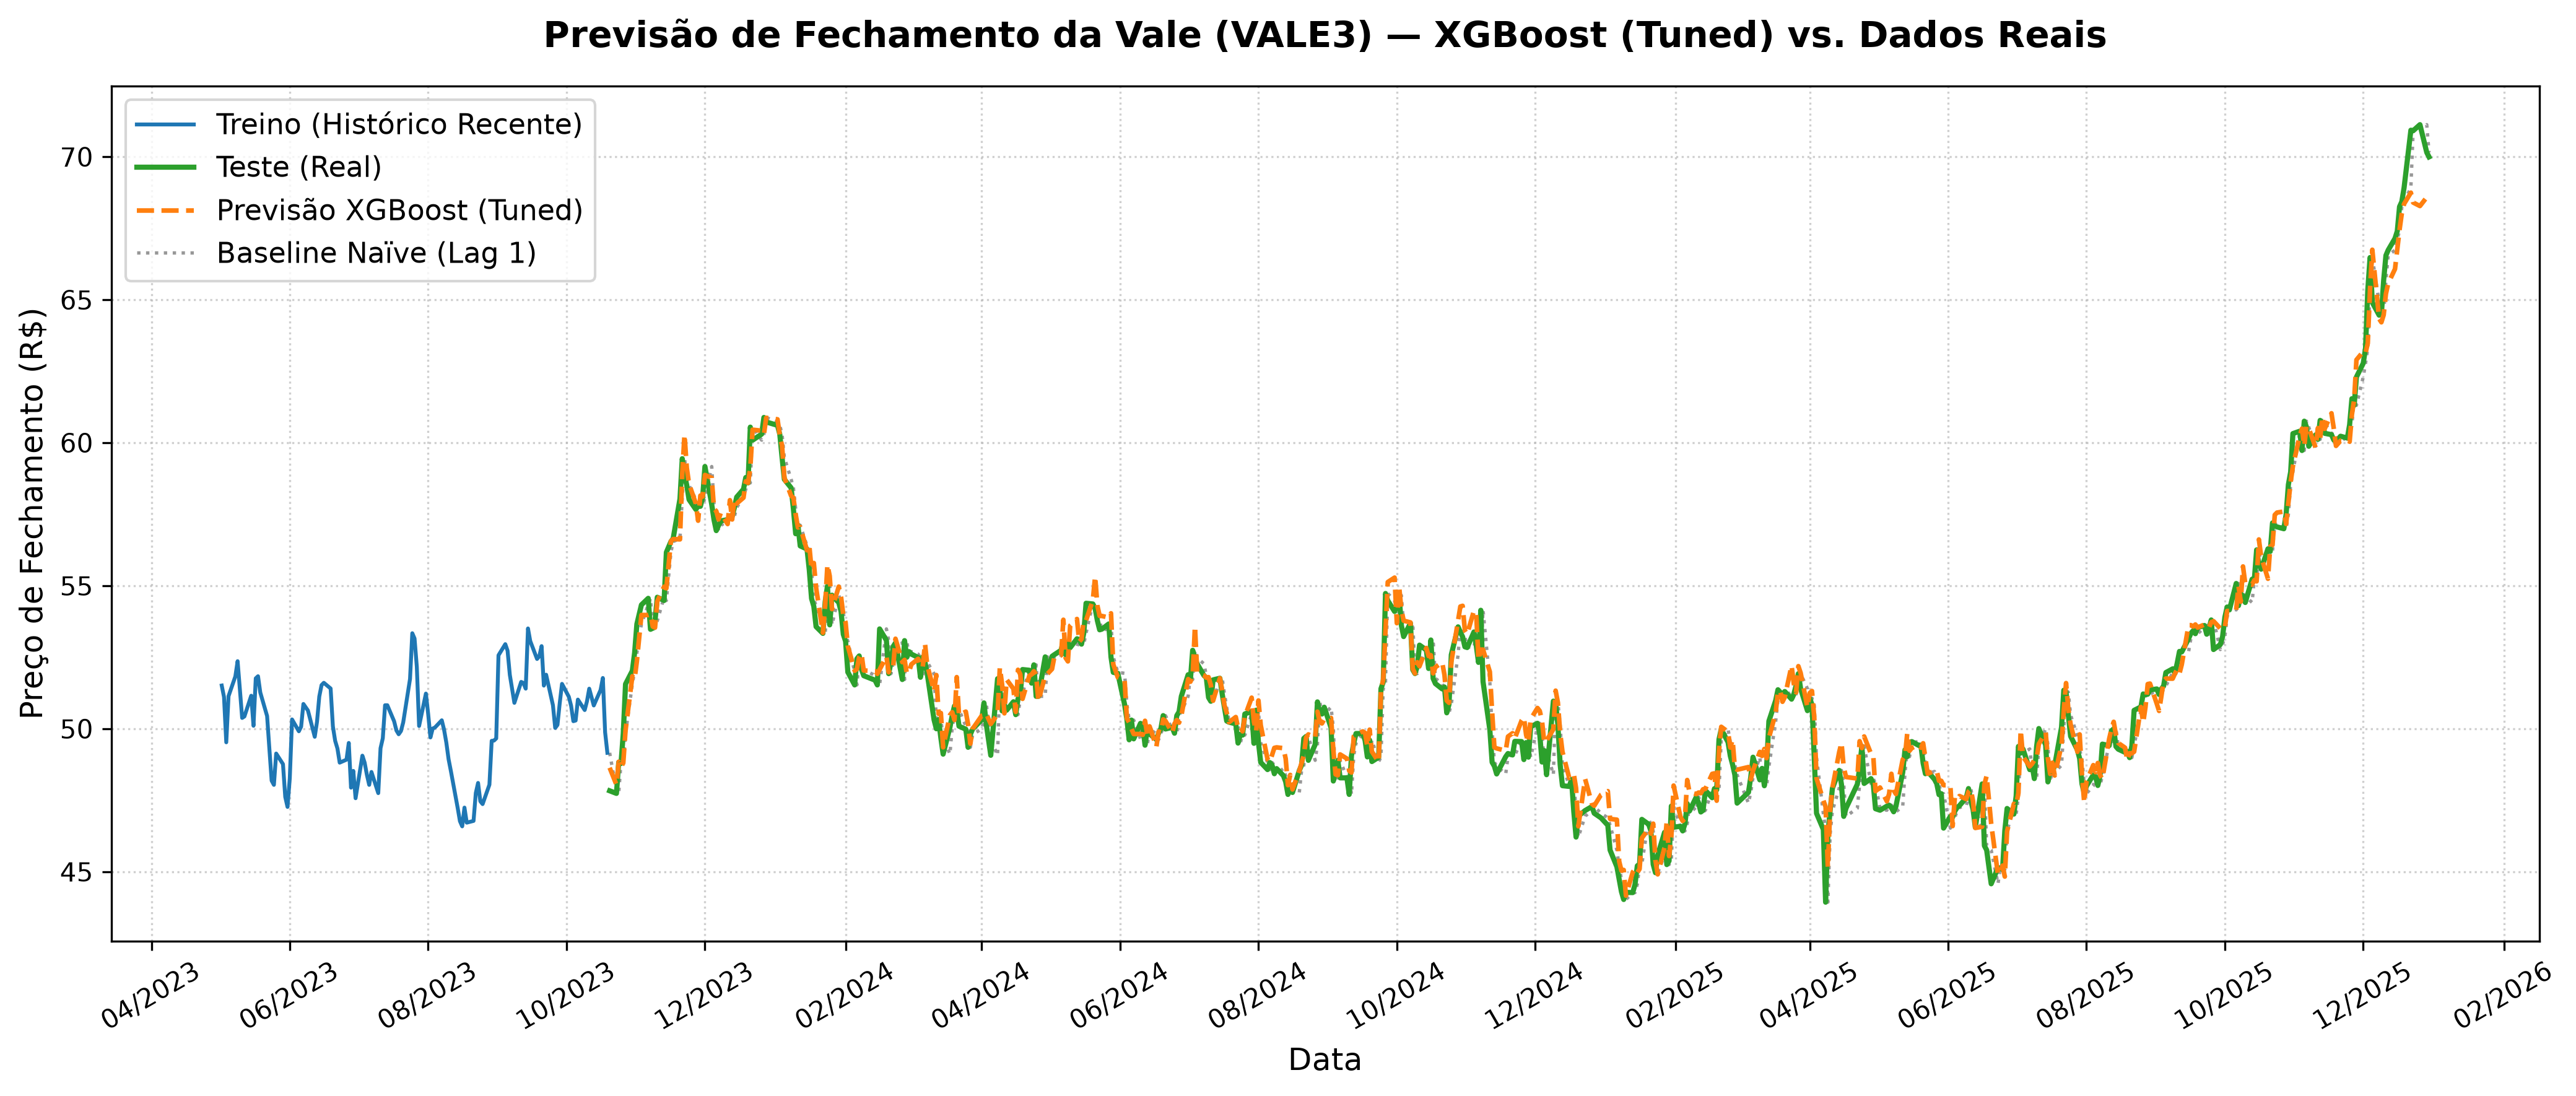

In [ ]:
res_xgbooster = run_xgbooster(train_vale, test_vale, "vale")
plot_forecast(
    train_vale, test_vale,
    predictions=res_xgbooster["predictions"],
    stock_name="vale",
    model_name="XGBoost (Tuned)",
    ticker_label="VALE3",
    company_name="Vale",
    baseline=res_xgbooster["ontem"],        # baseline naive (preço de ontem)
)

Trial 30 Complete [00h 00m 03s]
val_loss: 0.001052501960657537

Best val_loss So Far: 0.0005747784744016826
Total elapsed time: 00h 00m 49s
Melhores hiperparâmetros: {'n_layers': 1, 'units_0': 32, 'dropout_0': 0.0, 'learning_rate': 0.01, 'units_1': 192, 'dropout_1': 0.1, 'units_2': 224, 'dropout_2': 0.30000000000000004, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0022'}
Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0256 - mae: 0.0978 - val_loss: 0.0015 - val_mae: 0.0293
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0011 - mae: 0.0253 - val_loss: 0.0011 - val_mae: 0.0268
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.2511e-04 - mae: 0.0168 - val_loss: 9.7892e-04 - val_mae: 0.0238
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.8176e-04 - mae: 0.0140 - val_loss: 8.0179e-04 - val_mae: 0.0230
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 3.1514e-04 - mae: 0.0124 

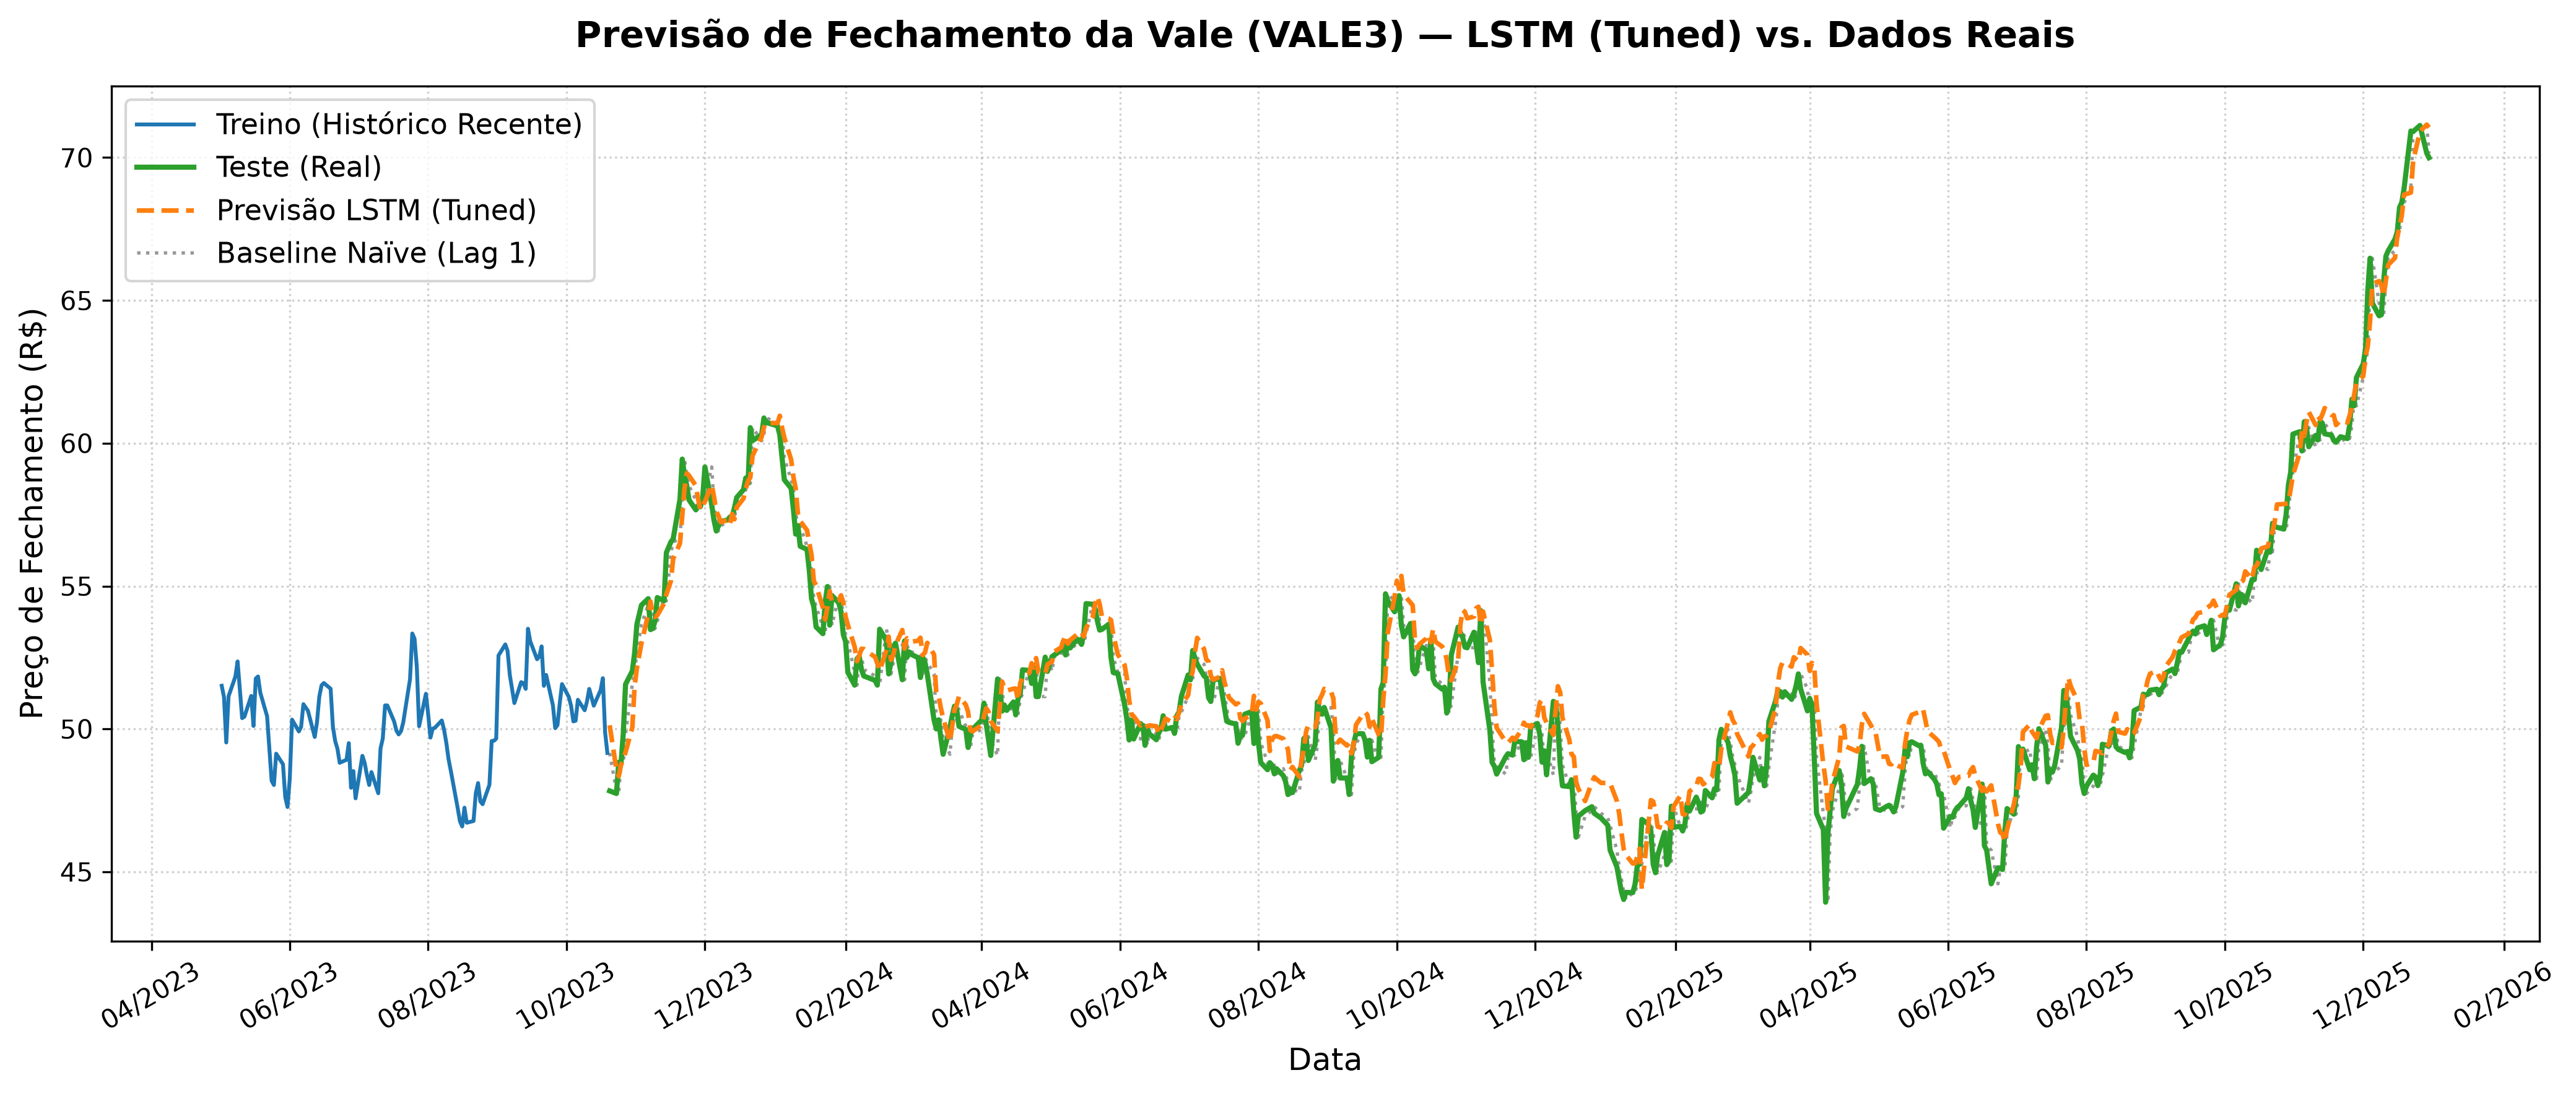

In [ ]:
res_lstm = run_lstm(train_vale, test_vale, "vale", max_epochs=10)
plot_forecast(train_vale, test_vale, res_lstm["predictions"], "vale",
              model_name="LSTM (Tuned)", ticker_label="VALE3",
              company_name="Vale", baseline=res_lstm["ontem"])

In [ ]:
tab_vale = explain_variables(res)
tab_vale.head(10)

NameError: name 'explain_variables' is not defined

In [ ]:
tab_vale = explain_variables(res_xgbooster)
tab_vale.head(10)

In [ ]:
tab_vale = explain_variables(res_lstm)
tab_vale.head(10)